# Maps and policy priorities: manuscript figures

Regenerate the main overview and the two supplementary case figures from the results of notebook 20. All inputs are included, so this notebook runs independently in a fresh kernel. It draws each figure from the supplied coordinates and tables, displays the live figure, and saves PDF and PNG versions in `outputs/figures/current/`.

**Inputs:** `outputs/tables/map20_*.csv`, the primary Chilean participant and proposal coordinates, and the frozen self-placement-3 coordinates in `data/processed/map_interpretation/101/`. Notebook 20 regenerates the analysis tables; notebooks 02 and 19 document the maps and the frozen case inputs.

The sectors, proposal selections, estimates and intervals are retained. No model is fitted and no contrast is re-estimated here. These are secondary evaluations on historically consulted choices. The pointwise intervals condition on the fitted map and fixed sectors.

The remaining manuscript figures are generated by notebooks 10–15. This notebook covers the new within-self-placement figures.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "data/processed").is_dir(), "Open from manuscript/ or its notebooks/ directory."
OUT = ROOT / "outputs/figures/current"
OUT.mkdir(parents=True, exist_ok=True)
inputs, outputs = {}, {}


def read(relative):
    path = ROOT / relative
    inputs[relative] = hashlib.sha256(path.read_bytes()).hexdigest()
    return pd.read_csv(path, float_precision="round_trip")


## Read the analysis results

The main overview shows three proposals from each original six-proposal case selection. Their numbering is local to this overview. Each supplementary figure retains all six proposals and its original within-case numbering. Purple and green always indicate proximity to the reference proposal within the specified self-placement group.

In [2]:
curves = read('outputs/tables/map20_global_curves.csv')
members = read('outputs/tables/map20_case_sector_memberships.csv')
profiles = read('outputs/tables/map20_case_profiles_all_fits.csv')
summary = read('outputs/tables/map20_case_summary.csv')
effects = read('outputs/tables/map20_case_choice_contrasts.csv').merge(
    summary[['self_placement','proposal_id','stable_interpretation']],
    on=['self_placement','proposal_id'],validate='one_to_one')
coords = read('outputs/models/Chile_dim2_seed101/coordsU.csv').set_index('uuid')
coords3 = read('data/processed/map_interpretation/101/coordinates.csv').set_index('uuid')
proposals = read('outputs/models/Chile_dim2_seed101/coordsP.csv').set_index('id')
assert len(proposals)==90 and proposals.index.is_unique
COLORS = {'Near':'#762A83','Middle':'#C7C7C7','Far':'#1B7837'}
MARKERS = {'Near':'o','Middle':'.','Far':'^'}
selection = [(3,37,1,'Constituent assembly'),(3,57,2,'Human-rights investigations'),
             (3,78,3,'End coattail-based election'),
             (7,86,4,'CAE debt cancellation'),(7,85,5,'Tax progressivity'),
             (7,20,6,'Reform the notary system')]
plt.rcParams.update({'font.size':8.5,'axes.labelsize':8.5,'xtick.labelsize':8,
                     'ytick.labelsize':8,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42})



In [3]:
def people_for(label):
    p=members.loc[members.politica.eq(label)&members.phase.eq('confirmation')].copy()
    assert len(p)=={3:1870,7:1551}[label]
    xy=(coords3 if label==3 else coords).loc[p.uuid,['z1','z2']].to_numpy()
    return p,xy

def map_panel(ax,label,highlight,annotations=False):
    people,xy=people_for(label)
    for sector in ['Middle','Far','Near']:
        use=people.sector_101.eq(sector).to_numpy()
        ax.scatter(xy[use,1],xy[use,0],s=6,alpha=.43,color=COLORS[sector],
                   marker=MARKERS[sector],linewidths=0,zorder=2)
    others=proposals.loc[~proposals.index.isin([p for p,n in highlight])]
    ax.scatter(others.z2,others.z1,s=15,marker='D',facecolor='none',
               edgecolor='#777777',linewidth=.55,alpha=.65,zorder=3)
    callouts={37:('Assembly',(.28,.035)),57:('Human rights',(.47,.42)),
              86:('CAE debt',(.61,.65)),85:('Tax progressivity',(.48,.055)),
              78:('Electoral rule',(.04,.84)),20:('Notary reform',(.02,.92))}
    for proposal,number in highlight:
        z=proposals.loc[proposal]
        ax.scatter(z.z2,z.z1,s=103,facecolor='white',edgecolor='black',lw=.8,zorder=8)
        ax.text(z.z2,z.z1,str(number),ha='center',va='center',fontsize=8,weight='bold',zorder=9)
        if annotations:
            name,offset=callouts[proposal]
            ax.annotate(name,xy=(z.z2,z.z1),xytext=offset,textcoords='data',fontsize=7.7,
                        va='center',bbox=dict(facecolor='white',edgecolor='none',alpha=.88,pad=1),
                        arrowprops=dict(arrowstyle='-',lw=.6,color='#555555',shrinkA=1,shrinkB=7),zorder=10)
    ax.set(xlim=(-.04,1.04),ylim=(-.04,1.04),aspect='equal',xlabel='Coordinate 1',ylabel='Coordinate 2')
    ax.set_xticks([0,.5,1]);ax.set_yticks([0,.5,1])
    return people

def show_and_save_figure(fig, name):
    display(fig)
    for extension in ("pdf", "png"):
        path = OUT / f"{name}.{extension}"
        fig.savefig(path, dpi=220, facecolor="white",
                    metadata={"CreationDate": None} if extension == "pdf" else None)
        outputs[path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
    plt.close(fig)


## Main overview

Panels A and B show confirmation participants and all 90 proposals. Panel C shows the adjusted near-minus-far choice contrasts and participant-bootstrap intervals. Panel D shows the global agreement curve, the other four fits and the within-self-placement shuffle comparison.

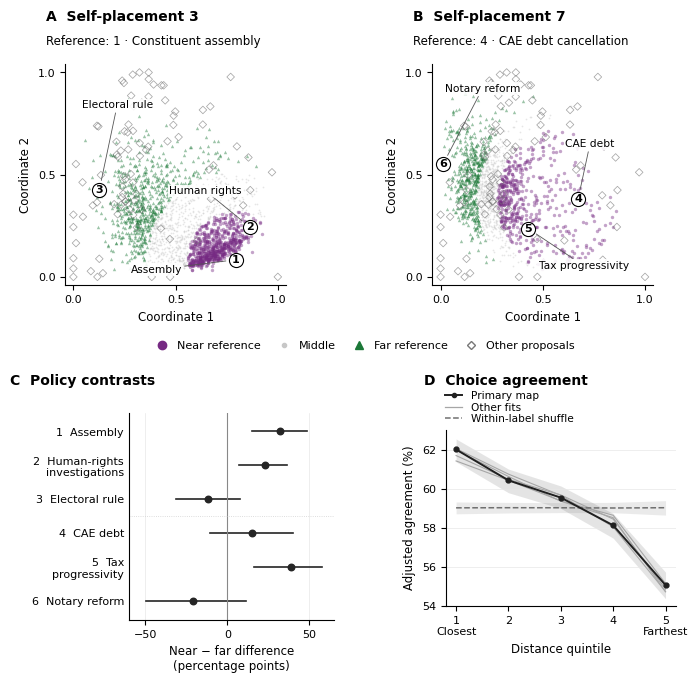

In [4]:
# Main figure: maps A/B above policy contrasts C and global concordance D.
fig=plt.figure(figsize=(7.2,6.9),facecolor='white')
axes={3:fig.add_axes([.09,.58,.36,.32]),7:fig.add_axes([.60,.58,.36,.32])}
for label,ax in axes.items():
    map_panel(ax,label,[(p,n) for lab,p,n,name in selection if lab==label],annotations=True)
    left=.09 if label==3 else .60
    fig.text(left,.963,('A' if label==3 else 'B')+f'  Self-placement {label}',fontsize=10,weight='bold')
    ref='1 · Constituent assembly' if label==3 else '4 · CAE debt cancellation'
    fig.text(left,.928,'Reference: '+ref,fontsize=8.5)
handles=[Line2D([0],[0],marker=MARKERS[s],ls='',color=COLORS[s],label=label)
         for s,label in [('Near','Near reference'),('Middle','Middle'),('Far','Far reference')]]
handles.append(Line2D([0],[0],marker='D',ls='',markerfacecolor='none',markeredgecolor='#777777',
                      markersize=4,label='Other proposals'))
fig.legend(handles=handles,frameon=False,ncol=4,loc='center',bbox_to_anchor=(.53,.492),
           fontsize=8,handletextpad=.35,columnspacing=1.1)

choice_ax=fig.add_axes([.205,.095,.285,.30])
global_ax=fig.add_axes([.645,.115,.32,.255])
fig.text(.04,.435,'C  Policy contrasts',fontsize=10,weight='bold')
fig.text(.615,.435,'D  Choice agreement',fontsize=10,weight='bold')
short_labels=['1  Assembly','2  Human-rights\ninvestigations','3  Electoral rule',
              '4  CAE debt','5  Tax\nprogressivity','6  Notary reform']
plot_rows=[]
for y,(label,proposal,number,name) in enumerate(selection):
    row=summary.loc[summary.self_placement.eq(label)&summary.proposal_id.eq(proposal)].iloc[0]
    assert row.sufficient_support
    choice_ax.plot([row.lower95_pp,row.upper95_pp],[y,y],color='#252525',lw=1.2)
    choice_ax.scatter(row.difference_pp,y,color='#252525',s=22,zorder=3)
    plot_rows.append({'number':number,'self_placement':label,'proposal_id':proposal,
                     'difference_pp':row.difference_pp,'lower95_pp':row.lower95_pp,'upper95_pp':row.upper95_pp,
                     'common_people':int(row.common_people),'common_choices':int(row.common_choices)})
choice_ax.axvline(0,color='#888888',lw=.8)
choice_ax.set(xlim=(-60,65),ylim=(5.55,-.55),xlabel='Near − far difference\n(percentage points)')
choice_ax.set_yticks(range(6),short_labels,fontsize=8)
choice_ax.axhline(2.5,color='#d2d2d2',lw=.6,ls=':')
choice_ax.set_xticks([-50,0,50]);choice_ax.tick_params(axis='y',length=0)
choice_ax.grid(axis='x',color='#e8e8e8',lw=.5);choice_ax.set_axisbelow(True)

primary=curves.loc[curves.seed.eq(101)].sort_values('quintile');x=primary.quintile.to_numpy()
for seed,group in curves.groupby('seed'):
    if seed!=101:
        group=group.sort_values('quintile')
        global_ax.plot(group.quintile,100*group.adjusted_agreement,color='#A6A6A6',lw=.8)
global_ax.fill_between(x,100*primary.shuffled_lower95,100*primary.shuffled_upper95,color='#DDDDDD',alpha=.6,lw=0)
global_ax.plot(x,100*primary.shuffled_mean,color='#707070',ls='--',lw=1.1)
global_ax.fill_between(x,100*primary.lower95,100*primary.upper95,color='#505050',alpha=.15,lw=0)
global_ax.plot(x,100*primary.adjusted_agreement,color='#202020',marker='o',ms=3.5,lw=1.4)
global_ax.set(xlim=(.8,5.2),ylim=(54,63),ylabel='Adjusted agreement (%)',xlabel='Distance quintile')
global_ax.set_xticks(x,['1\nClosest','2','3','4','5\nFarthest'])
global_ax.set_yticks([54,56,58,60,62]);global_ax.grid(axis='y',color='#E8E8E8',lw=.5)
global_ax.legend(handles=[
    Line2D([0],[0],color='#202020',marker='o',lw=1.4,ms=3,label='Primary map'),
    Line2D([0],[0],color='#A6A6A6',lw=.9,label='Other fits'),
    Line2D([0],[0],color='#707070',ls='--',lw=1.1,label='Within-label shuffle')],
    loc='lower left',bbox_to_anchor=(-.02,1.01),frameon=False,fontsize=7.6,
    handlelength=1.6,labelspacing=.15,borderaxespad=0)
show_and_save_figure(fig, 'map20_main_both_sides')



## Complete case figures

For each self-placement group, show its map, inferred priority ranks and reserved-choice contrasts. The dagger identifies a rank contrast whose direction changes across the five fitted maps. Sample sizes report the common-support people and choices for each contrast.

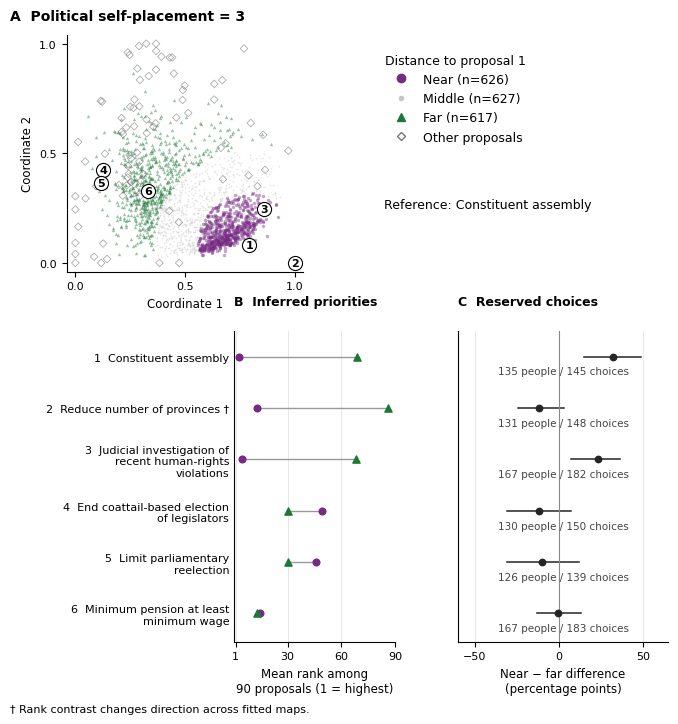

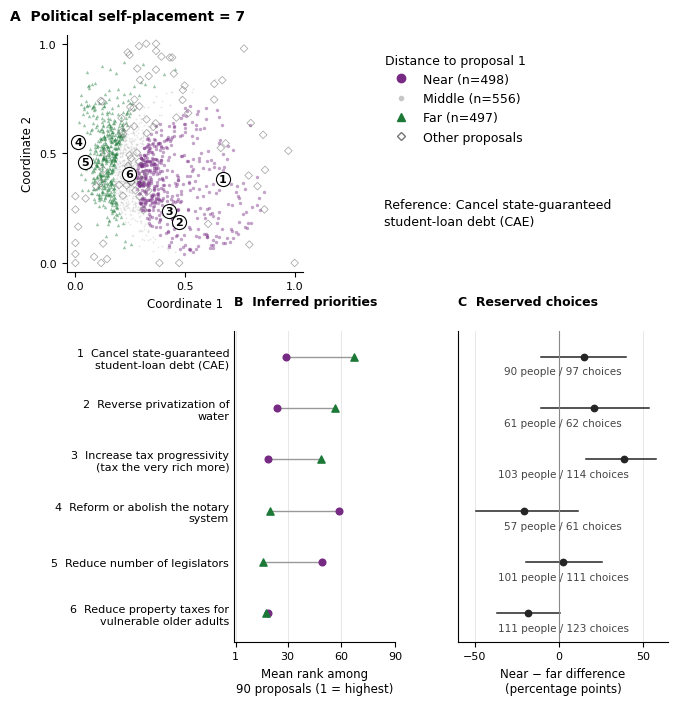

In [5]:
# Supplementary S15/S16: full original selections with the same proximity colors.
for label in [3,7]:
    rows=effects.loc[effects.self_placement.eq(label)].sort_values('figure_number')
    assert len(rows)==6
    prof=profiles.loc[profiles.self_placement.eq(label)&profiles.seed.eq(101)
                      &profiles.membership.eq('Fixed 101 sectors')&profiles.phase.eq('confirmation')]
    fig=plt.figure(figsize=(7,7.4),facecolor='white')
    map_ax=fig.add_axes([.08,.62,.42,.32]);rank_ax=fig.add_axes([.36,.12,.23,.42])
    choice_ax=fig.add_axes([.68,.12,.30,.42])
    people=map_panel(map_ax,label,[(int(r.proposal_id),int(r.figure_number)) for r in rows.itertuples()])
    fig.text(.04,.975,f'A  Political self-placement = {label}',weight='bold',fontsize=10,va='top')
    handles=[Line2D([0],[0],marker=MARKERS[s],ls='',color=COLORS[s],
                     label=f'{s} (n={people.sector_101.eq(s).sum():,})') for s in ['Near','Middle','Far']]
    handles.append(Line2D([0],[0],marker='D',ls='',markerfacecolor='none',markeredgecolor='#777777',
                          markersize=4,label='Other proposals'))
    fig.legend(handles=handles,frameon=False,loc='upper left',bbox_to_anchor=(.56,.93),
               title='Distance to proposal 1',title_fontsize=9,fontsize=9)
    anchor='Constituent assembly' if label==3 else 'Cancel state-guaranteed\nstudent-loan debt (CAE)'
    fig.text(.575,.72,'Reference: '+anchor,fontsize=9,va='top',linespacing=1.4)
    fig.text(.36,.575,'B  Inferred priorities',fontsize=9,weight='bold')
    fig.text(.68,.575,'C  Reserved choices',fontsize=9,weight='bold')
    names=[]
    for row in rows.itertuples():
        y=row.figure_number-1;suffix=' †' if not row.stable_interpretation else ''
        names.append(str(row.figure_number)+'  '+textwrap.fill(row.figure_label+suffix,29))
        rank=prof.loc[prof.proposal_id.eq(row.proposal_id)].set_index('sector').mean_rank
        rank_ax.plot([rank.Near,rank.Far],[y,y],color='#999999',lw=1)
        rank_ax.scatter(rank.Near,y,s=23,color=COLORS['Near'],marker='o',zorder=3)
        rank_ax.scatter(rank.Far,y,s=27,color=COLORS['Far'],marker='^',zorder=3)
        choice_ax.plot([100*row.lower95,100*row.upper95],[y,y],color='#252525',lw=1.1)
        choice_ax.scatter(100*row.difference,y,s=21,edgecolor='#252525',facecolor='#252525' if row.sufficient_support else 'white',zorder=3)
        choice_ax.text(.5,y+.29,f'{row.common_people} people / {row.common_choices} choices',
                       transform=choice_ax.get_yaxis_transform(),ha='center',va='center',fontsize=7.5,color='#444444')
    for ax in [rank_ax,choice_ax]:
        ax.set_ylim(5.55,-.5);ax.grid(axis='x',color='#DDDDDD',lw=.5)
        ax.tick_params(axis='y',length=0);ax.set_axisbelow(True)
    rank_ax.set_yticks(range(6),names,fontsize=8)
    rank_ax.set(xlim=(0,90),xlabel='Mean rank among\n90 proposals (1 = highest)');rank_ax.set_xticks([1,30,60,90])
    choice_ax.set_yticks(range(6),['']*6);choice_ax.axvline(0,color='#888888',lw=.8)
    choice_ax.set(xlim=(-60,65),xlabel='Near − far difference\n(percentage points)');choice_ax.set_xticks([-50,0,50])
    if (~rows.stable_interpretation).any():
        fig.text(.04,.025,'† Rank contrast changes direction across fitted maps.',fontsize=8)
    show_and_save_figure(fig, f'map20_case_selfplacement_{label}_distance')



## Plotted contrasts and input checksums

The table records the exact values displayed in the main overview. The manifest records the inputs and figure files used in this execution.

In [6]:
plotted_contrasts = pd.DataFrame(plot_rows)
display(plotted_contrasts)
plotted_contrasts.to_csv(OUT / "map20_both_sides_plot_contrasts.csv", index=False)

manifest = {
    "inputs_sha256": inputs,
    "outputs_sha256": outputs,
    "panel_order": {
        "A": "self-placement 3", "B": "self-placement 7",
        "C": "policy contrasts", "D": "global concordance",
    },
    "colors": COLORS,
    "overview_contrasts": plot_rows,
}
display(manifest)
(OUT / "map20_figures_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")


Out[6]: 3510


,number,self_placement,proposal_id,difference_pp,lower95_pp,upper95_pp,common_people,common_choices
0,1,3,37,32.400722,15.284832,48.676834,135,145
1,2,3,57,23.089922,7.114616,36.541128,167,182
2,3,3,78,-11.554779,-30.977350,7.548290,130,150
3,4,7,86,15.035239,-10.502108,39.733532,90,97
4,5,7,85,38.798951,16.278603,57.733393,103,114
5,6,7,20,-20.987654,-49.328169,11.596494,57,61


{'inputs_sha256': {'outputs/tables/map20_global_curves.csv': 'ee682da6b3d02ada1f0d71935175321157f47548d3b31d4d8f7dd11886e1dffd',
  'outputs/tables/map20_case_sector_memberships.csv': '72918c5a302235f160afde964c03fb57eef3aeb53e2d25f514a5976561d3d3b6',
  'outputs/tables/map20_case_profiles_all_fits.csv': 'fcd61cf645d0cdbd4f493840ac1b667579bf1b206626c53e260bd59e91993849',
  'outputs/tables/map20_case_summary.csv': '2187297d999b9faad3c18e1668b3d7e2d642a25a515441303b4e1755c9033e14',
  'outputs/tables/map20_case_choice_contrasts.csv': '34bb56df8875615d840034d1be5f1677a6e1939b5195cc96f3f531b506b8c530',
  'outputs/models/Chile_dim2_seed101/coordsU.csv': '3ac15cc2d5f05e21056d0b9a009d981efaf98be5d85f7f0dac55735825b97e2f',
  'data/processed/map_interpretation/101/coordinates.csv': 'e0ecd87a4e64ffff3c48cfcb0c151e11d0f7beec23d05b656c469e4aea03ba78',
  'outputs/models/Chile_dim2_seed101/coordsP.csv': 'fa482a1c94bdfa9869065d05512a70d24535abc43ee51ae9e03445ed987e8bb8'},
 'outputs_sha256': {'map20_main